In [1]:
import pandas as pd
import numpy as np

In [6]:
df=pd.read_csv('data.csv')
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,1,Clinton Hill Apartment Single Bedroom ! Pratt ~~,30610258,Santiago,Brooklyn,Clinton Hill,40.69591,-73.96284,Private room,58,2,1,9/23/2018,0.10,1,0
1,2,Andy Phillips,6180052,Andrian,Brooklyn,Fort Greene,40.68769,-73.97490,Private room,99,5,4,9/29/2017,0.17,1,250
2,3,"Stylish, Comfortable, and Affordable in Brooklyn",5957027,Zachary,Brooklyn,Crown Heights,40.67667,-73.91750,Entire home/apt,180,2,126,6/14/2019,3.74,1,74
3,4,15 min train ride to Times Sq and US OPEN,101602599,M,Queens,Woodside,40.74340,-73.90588,Entire home/apt,50,1,95,6/24/2019,5.63,2,0
4,5,Sunny 2 bdrm Park Slope Apt w/ Yard 3min to Su...,106168581,Jason,Brooklyn,South Slope,40.66600,-73.99020,Entire home/apt,210,4,88,7/4/2019,4.41,1,20


# Pre-Processing

removing columns - id,name,host_id,host_name,last_review,no of reviews, reviews per month, neigbourhood not related and text data  

In [7]:
df=df.drop(['id','name','host_id','host_name','neighbourhood','number_of_reviews','last_review','reviews_per_month'],axis=1)
df.head()

,neighbourhood_group,latitude,longitude,room_type,price,minimum_nights,calculated_host_listings_count,availability_365
0,Brooklyn,40.69591,-73.96284,Private room,58,2,1,0
1,Brooklyn,40.68769,-73.97490,Private room,99,5,1,250
2,Brooklyn,40.67667,-73.91750,Entire home/apt,180,2,1,74
3,Queens,40.74340,-73.90588,Entire home/apt,50,1,2,0
4,Brooklyn,40.66600,-73.99020,Entire home/apt,210,4,1,20


### Missing values

In [8]:
df.isnull().sum()

neighbourhood_group               0
latitude                          0
longitude                         0
room_type                         0
price                             0
minimum_nights                    0
calculated_host_listings_count    0
availability_365                  0
dtype: int64

In [10]:
#duplicates
df.duplicated().sum()

np.int64(0)

In [12]:
df.shape

(27379, 8)

### Outliers

In [23]:
def outliers(df,col):
    q1=df[col].quantile(.25)
    q3=df[col].quantile(.75)
    iqr=q3-q1
    lower= q1 - 1.5*iqr
    upper= q3 + 1.5*iqr
    return df[(df[col]<lower)|(df[col]>upper)]

In [24]:
outliers(df,'price')

,neighbourhood_group,latitude,longitude,room_type,price,minimum_nights,calculated_host_listings_count,availability_365
17,Manhattan,40.75403,-73.96714,Entire home/apt,714,28,49,250
35,Manhattan,40.73722,-74.00263,Entire home/apt,1500,3,1,54
42,Manhattan,40.74478,-73.98442,Entire home/apt,349,4,1,255
56,Manhattan,40.76515,-73.98586,Entire home/apt,389,1,1,0
75,Manhattan,40.75000,-73.99637,Entire home/apt,395,3,1,0
...,...,...,...,...,...,...,...,...
27286,Manhattan,40.76955,-73.95988,Entire home/apt,589,6,1,4
27326,Brooklyn,40.65716,-73.97550,Entire home/apt,450,4,2,87
27331,Manhattan,40.71895,-73.99793,Entire home/apt,5250,1,1,0
27355,Manhattan,40.74775,-73.99167,Entire home/apt,999,2,1,0


In [29]:
# lets use label encoder to convert to numerical data as the model can only have numerical data
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df['neighbourhood_group']=le.fit_transform(df['neighbourhood_group'])
df['room_type']=le.fit_transform(df['room_type'])
df.head()

,neighbourhood_group,latitude,longitude,room_type,price,minimum_nights,calculated_host_listings_count,availability_365
0,1,40.69591,-73.96284,1,58,2,1,0
1,1,40.68769,-73.97490,1,99,5,1,250
2,1,40.67667,-73.91750,0,180,2,1,74
3,3,40.74340,-73.90588,0,50,1,2,0
4,1,40.66600,-73.99020,0,210,4,1,20


### Splitting data

In [31]:
from sklearn.model_selection import train_test_split

x=df.drop('price',axis=1)
y=df['price']

xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=.2)
# splitting into "safe" along with train and test
xtrain,xsafe,ytrain,ysafe=train_test_split(xtrain,ytrain,test_size=.2)

### Scaling

In [32]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()

xtrain=sc.fit_transform(xtrain)
xtest=sc.transform(xtest)

## Model

In [33]:
#train model
from sklearn.linear_model import LinearRegression

regressor=LinearRegression()
regressor.fit(xtrain,ytrain)

LinearRegression()

## Prediction

In [40]:
ypred=regressor.predict(xtest)
ytest,ypred

(11531    150
 10688    195
 19721     68
 24242    100
 21557     40
         ... 
 18723    120
 7083     375
 6796     650
 12865    225
 8972      90
 Name: price, Length: 5476, dtype: int64,
 array([233.86271481, 185.80833597,  73.42638603, ..., 231.80370205,
        218.59325093, 225.04912059]))

## Accuracy

In [37]:
from sklearn.metrics import r2_score as rs
print('R2 Score : ',rs(ytest,ypred))

R2 Score :  0.16885703522815942


this low accuracy can be explained by the number of outliers in the data(1659 rows)

In [38]:
print('accuracy of linear regression on test set', 100*regressor.score(xtest,ytest))

accuracy of linear regression on test set 16.88570352281594


# Visualisation

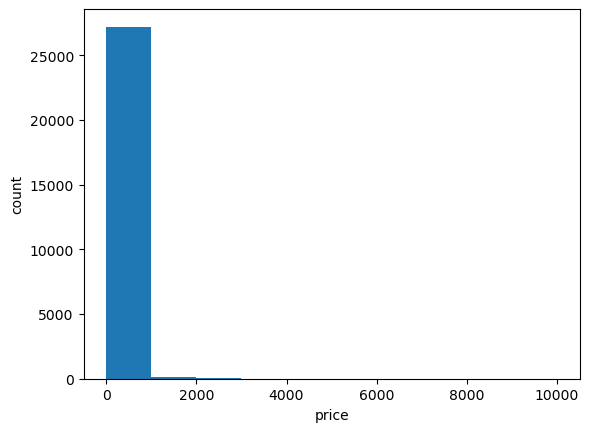

In [41]:
import matplotlib.pyplot as plt

plt.hist(df['price'])
plt.xlabel('price')
plt.ylabel('count')
plt.show()

<Axes: xlabel='minimum_nights', ylabel='price'>

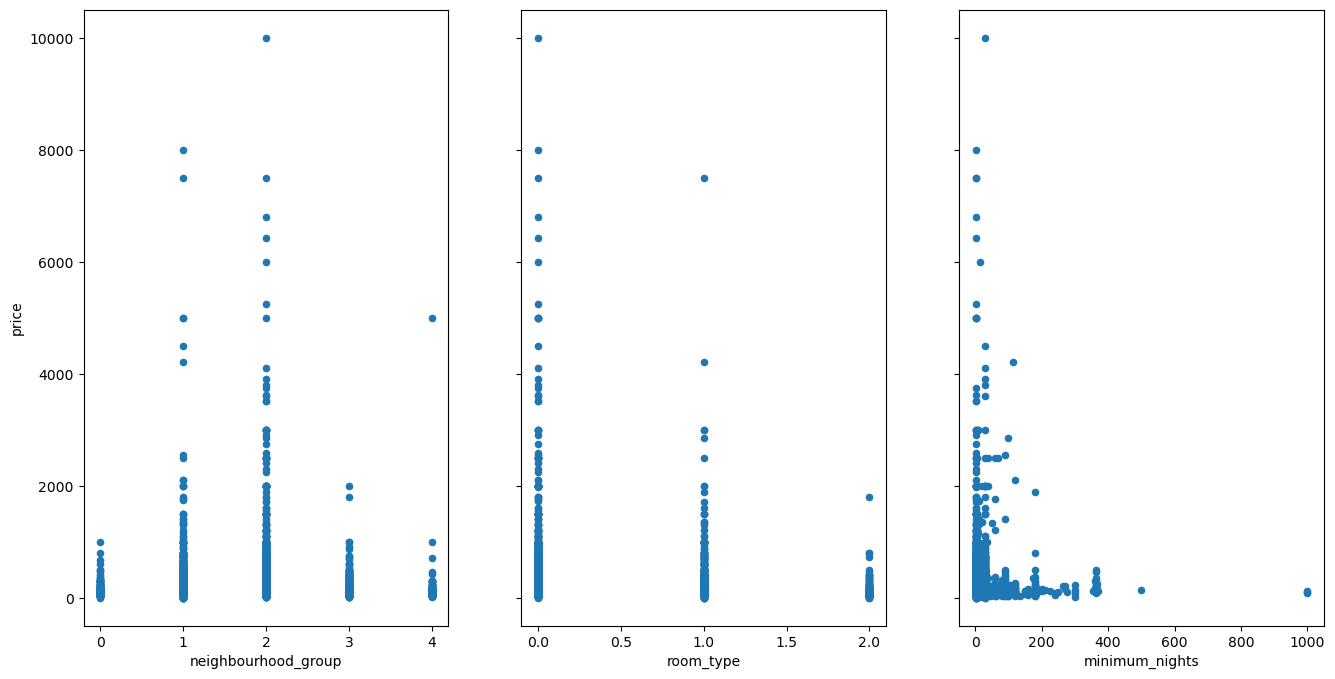

In [43]:
fig,axs=plt.subplots(1,3,sharey=True)
df.plot(kind='scatter',x='neighbourhood_group', y='price', ax=axs[0],figsize=(16,8))
df.plot(kind='scatter', x='room_type', y='price', ax=axs[1])
df.plot(kind='scatter', x='minimum_nights', y='price', ax=axs[2])